# 03: K-means Baseline: Is an LLM Needed at All?

**Why this notebook:** the original paper reports that plain **K-means on E5 embeddings** reaches ACC 62.21 on Massive-D, close to the LLM method with GPT-3.5 (64.12) and above our improved local-LLM results (Qwen 2.5: 49.4, Qwen3: 44.0). A reviewer will ask: *"Why use an LLM if K-means is cheaper and almost as good?"* This notebook measures K-means in **our own setup**, so we can answer that with our own numbers.

**What we test:**
1. **K-means with the true number of clusters (e.g. K = 18 for Massive-D):** the setting in the paper. It's an **unfair advantage**, because real users don't know K.
2. **K-means at the same granularity as our method:** K = the number of clusters our method produced on this dataset (read from `results.csv`). This is the fair comparison: same number of clusters, different method.

**To run another dataset:** change `DATA` and make sure its chosen threshold is listed in `CHOSEN`.
3. **K-means when K is unknown:** K chosen automatically with the silhouette score, using no true labels, like our method.

**Embeddings:** `all-MiniLM-L6-v2` (the small model we already use) and `e5-large-v2` (the E5 model family used in the paper).

**Everything is averaged over 5 random seeds**, because K-means results depend on the random start.

**No LLM is used here:** 0 LLM calls.

## 0. Setup

In [ ]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import evaluate as ev

DATA = "massive_intent"
SIZE = "small"
SEEDS = [0, 1, 2, 3, 4]
OURS = "A+B+C (merge + rescue)"
# Threshold chosen in notebook 02 per (dataset, model); add new runs here
CHOSEN = {("massive_scenario", "qwen2.5:7b"): 0.5, ("massive_scenario", "qwen3:8b"): 0.6,
          ("massive_intent", "qwen2.5:7b"): 0.4}

gold = ev.load_data("./dataset/", DATA, SIZE == "large")
texts = [g["input"] for g in gold]
y_true_raw = ev.get_labels(gold)
K_TRUE = len(set(y_true_raw))
# Number of clusters our method produced on this dataset (to compare K-means at the same K)
res0 = pd.read_csv("./results/results.csv")
ours = pd.concat([res0[(res0.dataset == DATA) & (res0.model == m) & (res0.method == OURS) & (res0.threshold == t)].tail(1)
                  for (d, m), t in CHOSEN.items() if d == DATA])
K_OURS = {r.model: int(r.predicted_clusters) for r in ours.itertuples()}
print(f"{len(texts)} texts, {K_TRUE} true clusters | our method's cluster counts: {K_OURS}")

2974 texts, 59 true clusters | our method's cluster counts: {'qwen2.5:7b': 59}


## 1. Compute the embeddings
**MiniLM** is small and fast. **E5-large** is larger (~1.3 GB download the first time) but much stronger, and it's the model family the paper's K-means baseline used. E5 expects each text to start with `"query: "`.

Embeddings are saved to disk, so rerunning the notebook doesn't recompute them. On a CPU, E5-large takes a few minutes for ~3,000 short texts.

In [ ]:
from sentence_transformers import SentenceTransformer
os.makedirs("./results/embeddings", exist_ok=True)

def get_embeddings(model_name, prefix=""):
    path = f"./results/embeddings/{DATA}_{model_name.split('/')[-1]}.npy"
    if os.path.exists(path):
        return np.load(path)
    t0 = time.time()
    model = SentenceTransformer(model_name)
    E = model.encode([prefix + t for t in texts], batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.save(path, E)
    print(f"{model_name}: {time.time() - t0:.0f} s")
    return E

EMB = {
    "MiniLM": get_embeddings("all-MiniLM-L6-v2"),
    "E5-large": get_embeddings("intfloat/e5-large-v2", prefix="query: "),
}
for k, E in EMB.items():
    print(k, E.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

all-MiniLM-L6-v2: 2 s


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

intfloat/e5-large-v2: 9 s
MiniLM (2974, 384)
E5-large (2974, 1024)


## 2. Run K-means
For each embedding model and each K, we run K-means with 5 seeds and average the scores. Scores use the same `evaluate.py` functions as the LLM notebooks, so all numbers are directly comparable.

In [ ]:
def score(pred_ids):
    y_true, _ = ev.convert_label_to_ids(y_true_raw)
    y_pred, k = ev.convert_label_to_ids([str(p) for p in pred_ids])
    return {m: float(v) for m, v in ev.clustering_score(y_true, y_pred).items()}

def run_kmeans(E, k):
    runs = []
    t0 = time.time()
    for seed in SEEDS:
        pred = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(E)
        runs.append(score(pred))
    mean = {m: round(np.mean([r[m] for r in runs]), 4) for m in ["ACC", "NMI", "ARI"]}
    std = {m + "_std": round(np.std([r[m] for r in runs]), 4) for m in ["ACC", "NMI", "ARI"]}
    return mean, std, (time.time() - t0) / 60

import io, contextlib
rows = []
settings = [("true K", K_TRUE)] + [(f"same K as ours ({m})", k) for m, k in K_OURS.items()]
for emb_name, E in EMB.items():
    for setting, k in settings:
        with contextlib.redirect_stdout(io.StringIO()):   # hide evaluate.py's prints
            mean, std, minutes = run_kmeans(E, k)
        rows.append({"embedding": emb_name, "setting": setting, "K": k, **mean, **std, "time_min": round(minutes, 2)})
        print(f"{emb_name:9s} {setting:28s} K={k:3d}  ACC {mean['ACC']:.3f}  NMI {mean['NMI']:.3f}  ARI {mean['ARI']:.3f}")
km = pd.DataFrame(rows)

MiniLM    true K                       K= 59  ACC 0.534  NMI 0.705  ARI 0.386
MiniLM    same K as ours (qwen2.5:7b)  K= 59  ACC 0.534  NMI 0.705  ARI 0.386
E5-large  true K                       K= 59  ACC 0.526  NMI 0.710  ARI 0.389
E5-large  same K as ours (qwen2.5:7b)  K= 59  ACC 0.526  NMI 0.710  ARI 0.389


## 3. K-means when K is unknown (silhouette)
**Why:** our LLM method doesn't know the true K; it finds the number of clusters on its own. To compare fairly, K-means must also choose K without the true labels. The **silhouette score** measures how well separated the clusters are, using only the embeddings. We try K from 5 to 100 and pick the K with the best silhouette.

MiniLM    best K by silhouette = 45  ACC 0.537  NMI 0.695  ARI 0.397
E5-large  best K by silhouette = 35  ACC 0.522  NMI 0.692  ARI 0.421


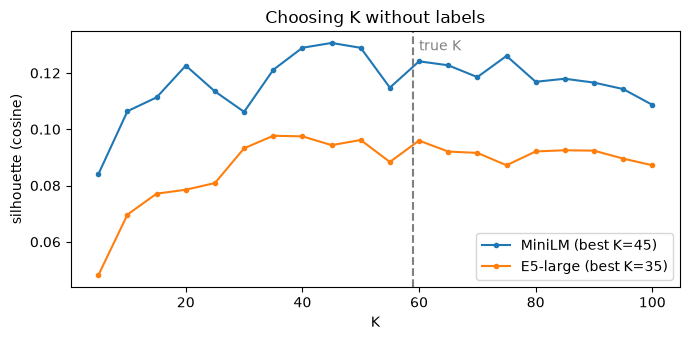

In [ ]:
K_RANGE = list(range(5, 101, 5))
sil_rows = []
for emb_name, E in EMB.items():
    sils = []
    for k in K_RANGE:
        pred = KMeans(n_clusters=k, n_init=5, random_state=0).fit_predict(E)
        sils.append(silhouette_score(E, pred, metric="cosine"))
    best_k = K_RANGE[int(np.argmax(sils))]
    sil_rows.append((emb_name, sils, best_k))
    with contextlib.redirect_stdout(io.StringIO()):
        mean, std, minutes = run_kmeans(E, best_k)
    rows.append({"embedding": emb_name, "setting": "K chosen by silhouette", "K": best_k, **mean, **std, "time_min": round(minutes, 2)})
    print(f"{emb_name:9s} best K by silhouette = {best_k}  ACC {mean['ACC']:.3f}  NMI {mean['NMI']:.3f}  ARI {mean['ARI']:.3f}")
km = pd.DataFrame(rows)

plt.figure(figsize=(7, 3.5))
for emb_name, sils, best_k in sil_rows:
    plt.plot(K_RANGE, sils, marker=".", label=f"{emb_name} (best K={best_k})")
plt.axvline(K_TRUE, ls="--", c="gray"); plt.text(K_TRUE + 1, plt.ylim()[1] * 0.95, "true K", color="gray")
plt.xlabel("K"); plt.ylabel("silhouette (cosine)"); plt.title("Choosing K without labels"); plt.legend()
plt.tight_layout(); plt.show()

## 4. Save and compare with our LLM method
The K-means rows are added to `results/results.csv` (model = `none`, 0 LLM calls), next to the LLM results.

In [ ]:
res = pd.read_csv("./results/results.csv")
new = pd.DataFrame([{
    "method": f"K-means ({r.embedding}, {r.setting})", "dataset": DATA, "model": "none", "n_texts": len(texts),
    "true_clusters": K_TRUE, "predicted_clusters": r.K, "ACC": r.ACC, "ARI": r.ARI, "NMI": r.NMI,
    "unsuccessful": 0, "llm_calls": 0, "time_min": r.time_min, "date": time.strftime("%Y-%m-%d %H:%M"),
} for r in km.itertuples()])
res = res[~((res.model == "none") & (res.dataset == DATA) & res.method.str.startswith("K-means"))]
res = pd.concat([res, new], ignore_index=True)
res.to_csv("./results/results.csv", index=False)

ours = ours.assign(name=[f"Ours: {r.model} (t={r.threshold})" for r in ours.itertuples()])
PAPER = {"massive_scenario": [(24, 0.6412, 0.6544, 0.4892), (18, 0.6221, 0.6542, 0.4769)],
         "massive_intent": [(71, 0.7175, 0.7800, 0.5686), (59, 0.5279, 0.7076, 0.3903)],
         "mtop_intent": [(83, 0.7218, 0.7878, 0.7193), (102, 0.3448, 0.7147, 0.2635)],
         "go_emotion": [(56, 0.3166, 0.2739, 0.1350), (27, 0.2214, 0.2126, 0.0964)],
         "arxiv_fine": [(122, 0.3878, 0.5743, 0.2055), (93, 0.3121, 0.5447, 0.1701)]}
cmp = pd.concat([
    ours[["name", "predicted_clusters", "ACC", "NMI", "ARI"]].rename(columns={"predicted_clusters": "K"}),
    km.assign(name="K-means " + km.embedding + ", " + km.setting)[["name", "K", "ACC", "NMI", "ARI"]],
    pd.DataFrame([dict(zip(["name", "K", "ACC", "NMI", "ARI"], [n] + list(v)))
                  for n, v in zip(["Paper: GPT-3.5 method", "Paper: K-means (E5), true K"], PAPER.get(DATA, []))]),
], ignore_index=True)
cmp

,name,K,ACC,NMI,ARI
0,Ours: qwen2.5:7b (t=0.4),59,0.4580,0.6636,0.3696
1,"K-means MiniLM, true K",59,0.5337,0.7048,0.3862
2,"K-means MiniLM, same K as ours (qwen2.5:7b)",59,0.5337,0.7048,0.3862
3,"K-means E5-large, true K",59,0.5263,0.7098,0.3894
4,"K-means E5-large, same K as ours (qwen2.5:7b)",59,0.5263,0.7098,0.3894
5,"K-means MiniLM, K chosen by silhouette",45,0.5367,0.6947,0.3974
6,"K-means E5-large, K chosen by silhouette",35,0.5225,0.6916,0.4215
7,Paper: GPT-3.5 method,71,0.7175,0.7800,0.5686
8,"Paper: K-means (E5), true K",59,0.5279,0.7076,0.3903


### Same number of clusters: K-means vs our method
The fairest comparison: K-means is given exactly the number of clusters our method produced.

In [ ]:
fair = []
for model, k in K_OURS.items():
    o = ours[ours.model == model].iloc[-1]
    for emb_name in EMB:
        r = km[(km.embedding == emb_name) & (km.K == k) & km.setting.str.startswith("same K")].iloc[0]
        fair.append({"K": k, "compare": f"Ours ({model}) vs K-means ({emb_name})",
                     "ACC ours": o.ACC, "ACC K-means": r.ACC, "NMI ours": o.NMI, "NMI K-means": r.NMI,
                     "ARI ours": o.ARI, "ARI K-means": r.ARI})
pd.DataFrame(fair)

,K,compare,ACC ours,ACC K-means,NMI ours,NMI K-means,ARI ours,ARI K-means
0,59,Ours (qwen2.5:7b) vs K-means (MiniLM),0.458,0.5337,0.6636,0.7048,0.3696,0.3862
1,59,Ours (qwen2.5:7b) vs K-means (E5-large),0.458,0.5263,0.6636,0.7098,0.3696,0.3894


## Findings: Massive-I (5 seeds)

| Setting | Method | K | ACC | NMI | ARI |
|---|---|---|---|---|---|
| True K (unrealistic) | K-means E5-large | 59 | 52.6 | 71.0 | 38.9 |
| Unknown K | K-means E5-large, silhouette | 35 | 52.2 | 69.2 | 42.1 |
| Unknown K | **Ours, Qwen 2.5 (t=0.4)** | 59 | 45.8 | 66.4 | 37.0 |
| – | GPT-3.5 method (paper) | 71 | 71.8 | 78.0 | 56.9 |

1. **On Massive-I, K-means beats our method on all three metrics**, by +6.8 ACC, +4.6 NMI and +1.9 ARI at the same K = 59. Unlike Massive-D, K-means is the stronger baseline on fine-grained intents.
2. **GPT-3.5 beats K-means by about 19 ACC points**, so the LLM approach itself is strong; the gap comes from the small 7B model, which struggles with intents that differ by a single action word ("set" vs "query" an alarm).
3. **Silhouette picks K = 35 on both datasets**, because Massive-D and Massive-I contain the same sentences and therefore the same embeddings. K-means cannot know whether 18 topics or 59 intents are wanted.
4. **Our method adapts the granularity to the task:** it produced 36 clusters on Massive-D (true 18) and exactly 59 on Massive-I (true 59), guided by the example labels. This is an advantage that embedding-only clustering does not have.